# 01 — Data loading and preparation (Real Doppler RAD-DAR)

**Input:** `../data/raw/` with one folder per class (`Cars`, `Drones`, `People`), each containing CSV files (one range-Doppler map per file, expected size 11 × 61).
**Output:** `../data/processed/raddar.npz` with the maps, labels, file names and a fixed train / validation / test split, used by all the following notebooks.

Steps:
1. Find all CSV files and their class.
2. Detect the file format (separator, header) on one file.
3. Load every map into one array of shape (N, 11, 61), check sizes and missing values.
4. Describe the values.
5. Create a reproducible, stratified train / validation / test split (70 / 15 / 15).
6. Save everything in one compressed file.

In [1]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedGroupKFold

SEED = 42
RAW = Path("../data/raw")
PROCESSED = Path("../data/processed"); PROCESSED.mkdir(parents=True, exist_ok=True)
FIG = Path("../figures"); FIG.mkdir(parents=True, exist_ok=True)

## 1. Find the files
The class is the name of the first folder under `raw/`. Inside each class, the files are stored in **one sub-folder per recording**, named after the time of the measurement (e.g. `13-13`), sometimes with a letter suffix (`13-13p`, `12-14f` / `12-14i`).

Maps from the same recording are consecutive radar frames of the same target, so they are almost identical. Folders with the same time but a different suffix most likely come from the same measurement session. The **session** (folder name without the letter suffix) is therefore kept as a **group**: all maps of one session must stay in the same set (train, validation or test).

In [2]:
class_names = sorted(d.name for d in RAW.iterdir() if d.is_dir())
print("Classes found:", class_names)

records = []
for label, cls in enumerate(class_names):
    for f in sorted((RAW / cls).rglob("*.csv")):
        rel = f.relative_to(RAW / cls)
        group = str(rel.parent) if rel.parent != Path(".") else ""
        records.append({"file": str(f.relative_to(RAW)), "class": cls, "label": label, "group": group})
files = pd.DataFrame(records)
files["session"] = files["group"].str.replace(r"[a-z]+$", "", regex=True)

print(f"\nTotal CSV files: {len(files)}")
print(files["class"].value_counts().to_string())
print("\nRecording folders and sessions per class:")
print(files.groupby("class").agg(folders=("group", "nunique"), sessions=("session", "nunique")).to_string())
files.head(10)

Classes found: ['Cars', 'Drones', 'People']

Total CSV files: 17485
class
People    6700
Cars      5720
Drones    5065

Recording folders and sessions per class:
        folders  sessions
class                    
Cars         27        15
Drones       21        21
People       32        16


,file,class,label,group,session
0,Cars\13-13\001.csv,Cars,0,13-13,13-13
1,Cars\13-13\002.csv,Cars,0,13-13,13-13
2,Cars\13-13\003.csv,Cars,0,13-13,13-13
3,Cars\13-13\004.csv,Cars,0,13-13,13-13
4,Cars\13-13\005.csv,Cars,0,13-13,13-13
5,Cars\13-13\006.csv,Cars,0,13-13,13-13
6,Cars\13-13\007.csv,Cars,0,13-13,13-13
7,Cars\13-13\008.csv,Cars,0,13-13,13-13
8,Cars\13-13\009.csv,Cars,0,13-13,13-13
9,Cars\13-13\010.csv,Cars,0,13-13,13-13


## 2. Detect the file format

In [3]:
first = RAW / files.loc[0, "file"]
sample = first.read_text()[:2000]
print("First lines of", first.name, ":\n")
print("\n".join(sample.splitlines()[:3]))

delimiter = csv.Sniffer().sniff(sample.splitlines()[0], delimiters=",;\t ").delimiter
try:
    [float(v) for v in sample.splitlines()[0].split(delimiter) if v.strip()]
    skip = 0
except ValueError:
    skip = 1   # first line is a header
print(f"\nDetected delimiter: {delimiter!r}   header lines skipped: {skip}")

First lines of 001.csv :

-113.9,-109.06,-109.85,-117.79,-120.07,-114.35,-123.82,-130,-120.38,-117.46,-120.67,-121.83,-116.63,-114.18,-115.05,-123.51,-123.43,-116.36,-125.05,-122.43,-119.37,-119.5,-113.96,-116.44,-123.18,-123.13,-115.56,-111.91,-110.91,-112.16,-116.94,-119.67,-116.25,-113.53,-120.33,-116.66,-117.68,-117.08,-119.89,-125.8,-115.18,-112.95,-115.71,-118.86,-124.29,-123.85,-120.57,-149.94,-122.23,-115.59,-116.36,-113.45,-125.1,-114.54,-123.59,-123.9,-121.01,-118.71,-120.11,-118.88,-114
-109.71,-110.72,-114.25,-115.19,-116.6,-118.53,-124.54,-119.57,-115.67,-122.1,-151.59,-118.05,-113.99,-118.27,-123.89,-119.67,-121.2,-118.03,-118.46,-164.65,-117.03,-113.39,-117.25,-127.28,-115.12,-117.57,-125.23,-111.73,-111.08,-112.38,-113.08,-116.06,-123.3,-120.93,-125.45,-117.48,-122.03,-140.4,-122.71,-117.17,-114.59,-115.96,-117.01,-123.84,-131.14,-124.94,-118.77,-113.7,-115.49,-123.86,-122.53,-118.56,-116.47,-112.64,-118.68,-121.73,-121.67,-117.67,-122.61,-123.44,-124.18
-110.34,-110.46

## 3. Load all maps

In [4]:
def load_map(path):
    return np.loadtxt(path, delimiter=None if delimiter == " " else delimiter, skiprows=skip, dtype=np.float32)

maps, shapes = [], []
for f in files["file"]:
    m = load_map(RAW / f)
    maps.append(m); shapes.append(m.shape)
files["shape"] = shapes

print("Map sizes found:\n" + files["shape"].value_counts().to_string())
expected = files["shape"].mode()[0]
bad = files["shape"] != expected
if bad.any():
    print(f"\nWARNING: {bad.sum()} files with a different size are removed:")
    print(files.loc[bad, ["file", "shape"]].head(20))

keep = ~bad.values
X = np.stack([m for m, k in zip(maps, keep) if k])
files = files[keep].reset_index(drop=True)
y = files["label"].to_numpy()
print(f"\nX shape: {X.shape}   y shape: {y.shape}")
print("Missing values (NaN):", int(np.isnan(X).sum()))

Map sizes found:
shape
(11, 61)    17485

X shape: (17485, 11, 61)   y shape: (17485,)
Missing values (NaN): 0


## 4. Values
Are the values linear power or already in dB (negative values, log scale)? This decides the normalisation used later.

In [5]:
print(pd.Series(X.ravel()).describe().round(3).to_string())
for i, cls in enumerate(class_names):
    v = X[y == i]
    print(f"{cls:8s} mean {v.mean():9.3f}   std {v.std():9.3f}   min {v.min():9.3f}   max {v.max():9.3f}")

count    1.173244e+07
mean    -1.119550e+02
std      9.599000e+00
min     -1.906900e+02
25%     -1.171400e+02
50%     -1.126700e+02
75%     -1.083400e+02
max     -3.865900e+01
Cars     mean  -111.635   std     8.471   min  -190.690   max   -42.733
Drones   mean  -114.442   std     6.889   min  -179.050   max   -51.927
People   mean  -110.347   std    11.662   min  -180.180   max   -38.659


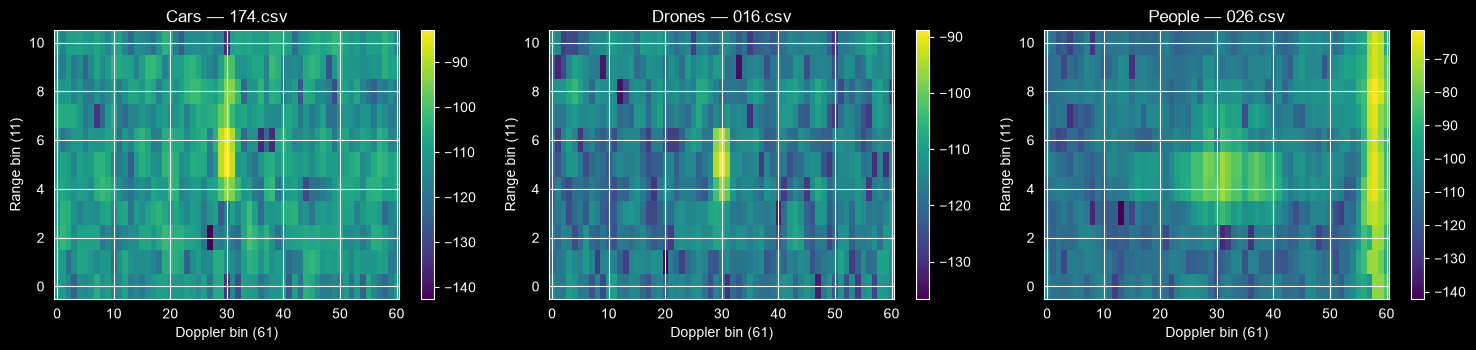

In [6]:
fig, axes = plt.subplots(1, len(class_names), figsize=(15, 3.6))
rng = np.random.default_rng(SEED)
for ax, (i, cls) in zip(axes, enumerate(class_names)):
    k = rng.choice(np.flatnonzero(y == i))
    im = ax.imshow(X[k], aspect="auto", cmap="viridis", origin="lower")
    ax.set(title=f"{cls} — {Path(files.loc[k, 'file']).name}", xlabel="Doppler bin (61)", ylabel="Range bin (11)")
    fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig(FIG / "dl_01_example_maps.png", dpi=200); plt.show()

## 5. Train / validation / test split (70 / 15 / 15)
- **Stratified**: each set keeps the same class proportions.
- **Grouped if possible**: if the classes contain sub-folders (recordings), all maps from one recording go to the same set, to avoid near-identical maps in training and test (data leakage).
- The split is saved once, so every model is trained and tested on exactly the same maps.

In [7]:
grouped = (files["group"] != "").all() and files.groupby("class")["group"].nunique().min() >= 5
idx = np.arange(len(y))

if grouped:
    groups = (files["class"] + "/" + files["session"]).to_numpy()
    sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)   # ~1/7 per fold
    folds = [te for _, te in sgkf.split(idx, y, groups)]
    test_idx, val_idx = folds[0], folds[1]
    train_idx = np.setdiff1d(idx, np.concatenate([test_idx, val_idx]))
    print("Grouped split (by measurement session)")
else:
    train_idx, tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
    val_idx, test_idx = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=SEED)
    print("Random stratified split (no recording information in the folders)")

split = pd.DataFrame({"set": ["train", "val", "test"],
                      "n": [len(train_idx), len(val_idx), len(test_idx)]})
for i, cls in enumerate(class_names):
    split[cls] = [int((y[s] == i).sum()) for s in (train_idx, val_idx, test_idx)]
split

Grouped split (by measurement session)


,set,n,Cars,Drones,People
0,train,12579,4035,3623,4921
1,val,2546,905,766,875
2,test,2360,780,676,904


In [8]:
# Check: no session appears in two different sets
sets = {"train": train_idx, "val": val_idx, "test": test_idx}
sess = {k: set(files.loc[v, "class"] + "/" + files.loc[v, "session"]) for k, v in sets.items()}
print("Sessions shared train/val:", len(sess["train"] & sess["val"]),
      "| train/test:", len(sess["train"] & sess["test"]), "| val/test:", len(sess["val"] & sess["test"]))
for k in sets:
    print(f"{k:5s}:", sorted(sess[k]))

Sessions shared train/val: 0 | train/test: 0 | val/test: 0
train: ['Cars/13-13', 'Cars/13-19', 'Cars/13-29', 'Cars/13-38', 'Cars/13-44', 'Cars/13-49', 'Cars/13-54', 'Cars/15-37', 'Cars/15-42', 'Cars/15-55', 'Cars/16-01', 'Drones/12-34', 'Drones/13-14', 'Drones/13-21', 'Drones/13-48', 'Drones/15-16', 'Drones/15-18', 'Drones/15-21', 'Drones/15-24', 'Drones/15-33', 'Drones/15-42', 'Drones/15-44', 'Drones/15-47', 'Drones/15-50', 'Drones/16-09', 'Drones/16-11', 'People/10-53', 'People/11-00', 'People/11-09', 'People/11-23', 'People/12-14', 'People/12-29', 'People/12-38', 'People/12-50', 'People/12-57', 'People/15-58', 'People/16-00', 'People/16-06']
val  : ['Cars/13-23', 'Cars/17-09', 'Drones/15-30', 'Drones/15-36', 'Drones/16-15', 'Drones/16-17', 'People/11-17', 'People/12-21']
test : ['Cars/15-48', 'Cars/16-07', 'Drones/12-41', 'Drones/15-38', 'People/10-45', 'People/12-43']


## 6. Save

In [9]:
np.savez_compressed(PROCESSED / "raddar.npz", X=X, y=y, class_names=np.array(class_names),
                    files=files["file"].to_numpy(), groups=files["group"].to_numpy(), sessions=files["session"].to_numpy(),
                    train_idx=train_idx, val_idx=val_idx, test_idx=test_idx)
print("Saved", PROCESSED / "raddar.npz", f"({(PROCESSED / 'raddar.npz').stat().st_size / 1e6:.1f} MB)")

Saved ..\data\processed\raddar.npz (25.4 MB)
